# Q1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Q1.1

In [ ]:
!nvcc -O2 -lineinfo -arch=sm_75 /content/vecAdd.cu -o /content/vecAdd

In [ ]:
!/content/vecAdd

result before GPU computation is 0
result after GPU computation is 33


In [ ]:
!cp -n /content/vecAdd.cu /content/vecAdd_original.cu
!ls -l /content/vecAdd_original.cu

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
-rw-r--r-- 1 root root 1327 Nov  3 14:47 /content/vecAdd_original.cu


In [ ]:
!nvcc -O2 -lineinfo -arch=sm_75 /content/vecAdd.cu -o /content/vecAdd

In [ ]:
!/content/vecAdd

N = 512
Threads per block = 256
Blocks = 2

First 5 results:
c[0] = 0.00 + 0.00 = 0.00
c[1] = 0.50 + 0.25 = 0.75
c[2] = 1.00 + 0.50 = 1.50
c[3] = 1.50 + 0.75 = 2.25
c[4] = 2.00 + 1.00 = 3.00

Last result:
c[511] = 255.50 + 127.75 = 383.25


### Q1.1 answer
because of c[i] = a[i] + b[i];
so, For a vector of length N
- Floating-point operations：N
- global memory reads：2N

## Q1.2


In [ ]:
!nvcc -O2 -lineinfo -arch=sm_75 /content/vecAdd.cu -o /content/vecAdd

In [ ]:
!/content/vecAdd

N = 512
Threads per block = 256
Blocks = 2
Total launched threads = 512

First 5 results:
c[0] = 0.00 + 0.00 = 0.00
c[1] = 0.50 + 0.25 = 0.75
c[2] = 1.00 + 0.50 = 1.50
c[3] = 1.50 + 0.75 = 2.25
c[4] = 2.00 + 1.00 = 3.00

Last result:
c[511] = 255.50 + 127.75 = 383.25


###Q1.2 answer：2 blocks and 512 CUDA threads are started.
For N=512, this implementation uses 256 threads per block.

The number of blocks is:
ceil(512 / 256) = 2.


## Q1.3

In [ ]:
!nvcc -O2 -lineinfo -arch=sm_75 /content/vecAdd.cu -o /content/vecAdd

In [ ]:
!/content/vecAdd

N = 512
Threads per block = 256
Blocks = 2
Total launched threads = 512

First 5 results:
c[0] = 0.00 + 0.00 = 0.00
c[1] = 0.50 + 0.25 = 0.75
c[2] = 1.00 + 0.50 = 1.50
c[3] = 1.50 + 0.75 = 2.25
c[4] = 2.00 + 1.00 = 3.00

Last result:
c[511] = 255.50 + 127.75 = 383.25


In [ ]:
!ncu --section Occupancy /content/vecAdd

==PROF== Connected to process 13048 (/content/vecAdd)
==PROF== Profiling "add" - 0: 0%....50%....100% - 1 pass
N = 512
Threads per block = 256
Blocks = 2
Total launched threads = 512

First 5 results:
c[0] = 0.00 + 0.00 = 0.00
c[1] = 0.50 + 0.25 = 0.75
c[2] = 1.00 + 0.50 = 1.50
c[3] = 1.50 + 0.75 = 2.25
c[4] = 2.00 + 1.00 = 3.00

Last result:
c[511] = 255.50 + 127.75 = 383.25
==PROF== Disconnected from process 13048
[13048] vecAdd@127.0.0.1
  add(const float *, const float *, float *, int) (2, 1, 1)x(256, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Occupancy
    ------------------------------- ----------- ------------
    Metric Name                     Metric Unit Metric Value
    ------------------------------- ----------- ------------
    Block Limit SM                        block           16
    Block Limit Registers                 block           16
    Block Limit Shared Mem                block           16
    Block Limit Warps                     block        

### Q1.3 Achieved Occupancy = 24.76%

## Q1.4


In [ ]:
!nvcc -O2 -lineinfo -arch=sm_75 /content/vecAdd.cu -o /content/vecAdd

In [ ]:
!/content/vecAdd


CPU/GPU validation:
Exact mismatches = 0
Max absolute error = 0
Failed elements = 0
Validation = PASS
N = 263149
Threads per block = 256
Blocks = 1028
Total launched threads = 263168

First 5 results:
c[0] = 0.00 + 0.00 = 0.00
c[1] = 0.50 + 0.25 = 0.75
c[2] = 1.00 + 0.50 = 1.50
c[3] = 1.50 + 0.75 = 2.25
c[4] = 2.00 + 1.00 = 3.00

Last result:
c[263148] = 131574.00 + 65787.00 = 197361.00


###Q1.4 Answer
The program still runs correctly and no repairs are needed

## Q1.5 Answer
Blocks: 1028;
Threads = 1028*256 = 263168

## Q1.6

In [ ]:
!ncu --section Occupancy /content/vecAdd


==PROF== Connected to process 19191 (/content/vecAdd)
==PROF== Profiling "add" - 0: 0%....50%....100% - 1 pass

CPU/GPU validation:
Exact mismatches = 0
Max absolute error = 0
Failed elements = 0
Validation = PASS
N = 263149
Threads per block = 256
Blocks = 1028
Total launched threads = 263168

First 5 results:
c[0] = 0.00 + 0.00 = 0.00
c[1] = 0.50 + 0.25 = 0.75
c[2] = 1.00 + 0.50 = 1.50
c[3] = 1.50 + 0.75 = 2.25
c[4] = 2.00 + 1.00 = 3.00

Last result:
c[263148] = 131574.00 + 65787.00 = 197361.00
==PROF== Disconnected from process 19191
[19191] vecAdd@127.0.0.1
  add(const float *, const float *, float *, int) (1028, 1, 1)x(256, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Occupancy
    ------------------------------- ----------- ------------
    Metric Name                     Metric Unit Metric Value
    ------------------------------- ----------- ------------
    Block Limit SM                        block           16
    Block Limit Registers                 block    

### Q1.6 Answer
Achieved Occupancy : 80.17%

## Q1.7

In [ ]:
!cp -n /content/vecAdd.cu /content/vecAdd_before_timing.cu

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [20]:
!nvcc -O2 -lineinfo -arch=sm_75 /content/vecAdd.cu -o /content/vecAdd

In [21]:
!/content/vecAdd 263149


Average timing over 10 repetitions:
H2D = 0.652003 ms
Kernel = 0.030684 ms
D2H = 0.325418 ms
TIMING,263149,0.652003288,0.030684471,0.325417519

CPU/GPU validation:
Exact mismatches = 0
Max absolute error = 0
Failed elements = 0
Validation = PASS
N = 263149
Threads per block = 256
Blocks = 1028
Total launched threads = 263168

First 5 results:
c[0] = 0.00 + 0.00 = 0.00
c[1] = 0.50 + 0.25 = 0.75
c[2] = 1.00 + 0.50 = 1.50
c[3] = 1.50 + 0.75 = 2.25
c[4] = 2.00 + 1.00 = 3.00

Last result:
c[263148] = 131574.00 + 65787.00 = 197361.00


In [22]:
import subprocess
import csv

sizes = [
    512,
    4096,
    16384,
    65536,
    263149,
    524288,
    1048576,
    2097152,
    4194304,
    8388608,
    16777216,
    33554432,
]

rows = []

for n in sizes:
    result = subprocess.run(
        ["/content/vecAdd", str(n)],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"N={n} 运行或验证失败")

    if "Validation = PASS" not in result.stdout:
        raise RuntimeError(f"N={n} 未找到验证通过信息")

    timing_lines = [
        line for line in result.stdout.splitlines()
        if line.startswith("TIMING,")
    ]

    if len(timing_lines) != 1:
        raise RuntimeError(f"N={n} 的计时输出异常")

    _, n_text, h2d, kernel, d2h = timing_lines[0].split(",")

    rows.append([
        int(n_text),
        float(h2d),
        float(kernel),
        float(d2h)
    ])

    print(
        f"N={n:>8} | "
        f"H2D={float(h2d):.6f} ms | "
        f"Kernel={float(kernel):.6f} ms | "
        f"D2H={float(d2h):.6f} ms | PASS"
    )

csv_path = "/content/q1_7_timings.csv"

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["N", "h2d_ms", "kernel_ms", "d2h_ms"])
    writer.writerows(rows)

print(f"\n已保存：{csv_path}")

N=     512 | H2D=0.014234 ms | Kernel=0.009012 ms | D2H=0.008678 ms | PASS
N=    4096 | H2D=0.029159 ms | Kernel=0.009632 ms | D2H=0.014400 ms | PASS
N=   16384 | H2D=0.071764 ms | Kernel=0.011325 ms | D2H=0.030446 ms | PASS
N=   65536 | H2D=0.165272 ms | Kernel=0.011039 ms | D2H=0.088906 ms | PASS
N=  263149 | H2D=0.627732 ms | Kernel=0.014782 ms | D2H=0.313091 ms | PASS
N=  524288 | H2D=1.020288 ms | Kernel=0.027370 ms | D2H=0.530148 ms | PASS
N= 1048576 | H2D=1.984882 ms | Kernel=0.054336 ms | D2H=1.003909 ms | PASS
N= 2097152 | H2D=3.832817 ms | Kernel=0.109553 ms | D2H=1.962233 ms | PASS
N= 4194304 | H2D=7.158899 ms | Kernel=0.206065 ms | D2H=3.621626 ms | PASS
N= 8388608 | H2D=14.644623 ms | Kernel=0.401425 ms | D2H=7.257056 ms | PASS
N=16777216 | H2D=28.782392 ms | Kernel=0.786209 ms | D2H=14.281893 ms | PASS
N=33554432 | H2D=62.069130 ms | Kernel=1.719594 ms | D2H=30.786943 ms | PASS

已保存：/content/q1_7_timings.csv


,N,h2d_ms,kernel_ms,d2h_ms
0,512,0.014234,0.009012,0.008678
1,4096,0.029159,0.009632,0.014400
2,16384,0.071764,0.011325,0.030446
3,65536,0.165272,0.011039,0.088906
4,263149,0.627732,0.014782,0.313091
5,524288,1.020288,0.027370,0.530148
6,1048576,1.984882,0.054336,1.003909
7,2097152,3.832817,0.109553,1.962233
8,4194304,7.158899,0.206065,3.621626
9,8388608,14.644623,0.401425,7.257056


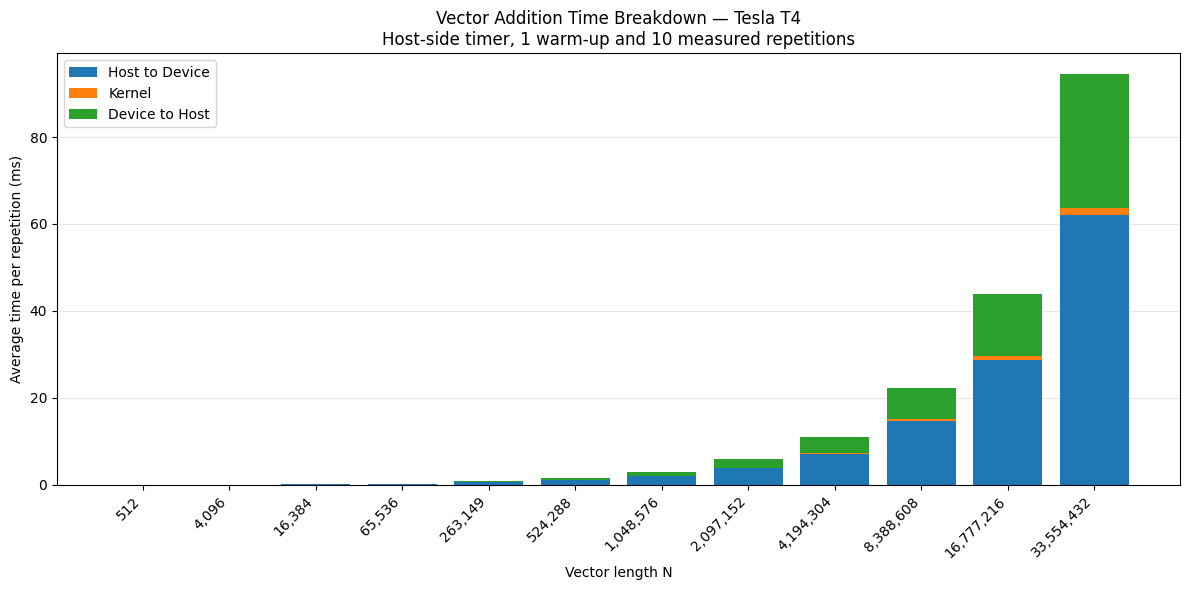

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/q1_7_timings.csv")
display(df)

x = np.arange(len(df))

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x, df["h2d_ms"],
    label="Host to Device"
)

ax.bar(
    x, df["kernel_ms"],
    bottom=df["h2d_ms"],
    label="Kernel"
)

ax.bar(
    x, df["d2h_ms"],
    bottom=df["h2d_ms"] + df["kernel_ms"],
    label="Device to Host"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{n:,}" for n in df["N"]],
    rotation=45,
    ha="right"
)

ax.set_xlabel("Vector length N")
ax.set_ylabel("Average time per repetition (ms)")
ax.set_title(
    "Vector Addition Time Breakdown — Tesla T4\n"
    "Host-side timer, 1 warm-up and 10 measured repetitions"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("/content/q1_7_time_breakdown.png", dpi=300)

plt.show()

## Q1.8
The calculation results of CPU and GPU are exactly the same.
I think this is because the CPU and GPU use the same float data and the same calculation method, so their results are the same in this experiment. Although the GPU uses multiple threads, each thread does not affect the calculations of the other threads. Therefore, the GPU and CPU results are the same in this experiment.